# Self-harm content scoring for educational prompts

This notebook trains a CPU baseline for the historical `SH` label in OpenAI's public moderation benchmark. Interpret the output as a score for that content label. A person's intent, level of risk and need for support require additional context.

The archive contains sensitive material. The notebook fetches it into memory and displays only aggregate results. It uses no student data. See [RESEARCH.md](RESEARCH.md) for sources and limitations.

In [1]:
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    PrecisionRecallDisplay,
    average_precision_score,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
)

# nbconvert runs the kernel in the notebook directory.
ai_root = Path.cwd().resolve()
if ai_root.name == "notebooks":
    ai_root = ai_root.parent
elif (ai_root / "AI").is_dir():
    ai_root = ai_root / "AI"
sys.path.insert(0, str(ai_root))

from research.benchmark import REVISION, load_benchmark
from research.experiment_protocol import prompt_development_scores, prompt_split, prompt_threshold
from prompt_model import MODEL_PATH, SEED, build_model, export_model, score_prompts

prompts, labels, counts = load_benchmark()
labels = np.asarray(labels)
dev, test = prompt_split(labels)
dev_prompts = [prompts[i] for i in dev]
test_prompts = [prompts[i] for i in test]
y_dev, y_test = labels[dev], labels[test]

print(json.dumps({
    "dataset_revision": REVISION,
    **counts,
    "seed": SEED,
    "development": {"rows": len(dev), "positive": int(y_dev.sum())},
    "holdout": {"rows": len(test), "positive": int(y_test.sum())},
}, indent=2))

{
  "dataset_revision": "d3938df6ce8b06c2907f92c6084d8192da61b9aa",
  "source_rows": 1680,
  "unlabeled_rows": 233,
  "duplicate_rows": 3,
  "conflicting_rows": 0,
  "usable_rows": 1444,
  "positive_rows": 51,
  "seed": 42,
  "development": {
    "rows": 1155,
    "positive": 41
  },
  "holdout": {
    "rows": 289,
    "positive": 10
  }
}


## Fit and choose an operating point

The pipeline converts character 3–5-grams into hashed features, applies TF-IDF, and fits class-weighted logistic regression. The IDF and classifier are fitted inside each development fold. The threshold maximizes F₂ on five-fold out-of-fold scores. F₂ gives recall more weight than precision. The held-out split and synthetic cases play no part in this choice.

In [2]:
dev_scores = prompt_development_scores(dev_prompts, y_dev)
threshold = prompt_threshold(y_dev, dev_scores)
best_f2 = fbeta_score(y_dev, dev_scores >= threshold, beta=2)
model = build_model().fit(dev_prompts, y_dev)

print(json.dumps({
    "development_oof_average_precision": round(average_precision_score(y_dev, dev_scores), 3),
    "development_oof_best_f2": round(best_f2, 3),
    "selected_threshold": round(threshold, 6),
}, indent=2))

{
  "development_oof_average_precision": 0.659,
  "development_oof_best_f2": 0.708,
  "selected_threshold": 0.413605
}


{
  "holdout_average_precision": 0.659,
  "constant_score_average_precision": 0.035,
  "precision": 0.533,
  "recall": 0.8,
  "f1": 0.64,
  "true_positive": 8,
  "false_positive": 7,
  "true_negative": 272,
  "false_negative": 2
}


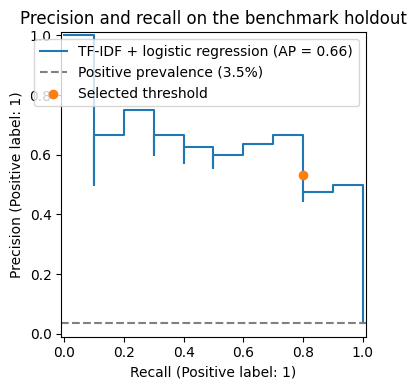

In [3]:
def threshold_metrics(y, scores):
    flagged = scores >= threshold
    tn, fp, fn, tp = confusion_matrix(y, flagged, labels=[0, 1]).ravel()
    return {
        "precision": round(precision_score(y, flagged, zero_division=0), 3),
        "recall": round(recall_score(y, flagged, zero_division=0), 3),
        "f1": round(f1_score(y, flagged, zero_division=0), 3),
        "true_positive": int(tp), "false_positive": int(fp),
        "true_negative": int(tn), "false_negative": int(fn),
    }


test_scores = model.predict_proba(test_prompts)[:, 1]
prior = float(y_test.mean())
print(json.dumps({
    "holdout_average_precision": round(average_precision_score(y_test, test_scores), 3),
    "constant_score_average_precision": round(prior, 3),
    **threshold_metrics(y_test, test_scores),
}, indent=2))

fig, ax = plt.subplots(figsize=(6.4, 4.0))
PrecisionRecallDisplay.from_predictions(y_test, test_scores, name="TF-IDF + logistic regression", ax=ax)
ax.axhline(prior, linestyle="--", color="gray", label=f"Positive prevalence ({prior:.1%})")
predicted = test_scores >= threshold
ax.scatter(
    recall_score(y_test, predicted, zero_division=0),
    precision_score(y_test, predicted, zero_division=0),
    label="Selected threshold", color="tab:orange", zorder=3,
)
ax.set_title("Precision and recall on the benchmark holdout")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

## Independent classroom prompts

These authored prompts check three situations. First-person signals include direct and indirect statements without any descriptions of methods. Ordinary course prompts include frustrating language and a technical use of “kill.” Mention-only prompts include academic discussion and supporting someone else. The synthetic labels indicate whether the speaker expresses a signal about themselves, a narrower target than the historical benchmark label. The counts are illustrative and support no estimate for actual student traffic.

In [4]:
from research.classroom_probes import CLASSROOM_CASES

for group, texts in CLASSROOM_CASES.items():
    scores = model.predict_proba(texts)[:, 1]
    print(f"{group}: {int(np.sum(scores >= threshold))}/{len(texts)} flagged")

first_person_signal: 3/5 flagged
course_prompt: 0/5 flagged
mention_only: 0/5 flagged


In [5]:
export_model(model, threshold)
exported_scores, exported_threshold = score_prompts(test_prompts)
np.testing.assert_allclose(exported_scores, test_scores, atol=1e-12, rtol=0)
assert exported_threshold == threshold
print(f"Exported {MODEL_PATH.name} ({MODEL_PATH.stat().st_size:,} bytes).")
print(f"Reloaded artifact reproduced all {len(test_scores)} held-out scores.")

Exported self-harm-text-model.npz (443,483 bytes).
Reloaded artifact reproduced all 289 held-out scores.
